In [2]:
from pathlib import Path
from pydantic import BaseModel, Field, model_validator
from dataclasses import dataclass,field
from typing import List, Set, Dict,Tuple,Union,Optional

def f1_calculate(precision: float, recall: float) -> float:
    if precision + recall == 0:
        return 0.0
    return 2 * (precision * recall) / (precision + recall)

class VulnPair(BaseModel):
    files: List[Path] = Field(default_factory=list)
    ground_truth: Set[str] = Field(default_factory=set)
    detected: Set[str] = Field(default_factory=set)
    score_board: Dict[str, float] = Field(default_factory=dict)
    score: float = 0.0

    @model_validator(mode='after')
    def calculate_score(self):
        score = 0
        for det in self.detected:
            score+= self.score_board.get(det, 0)

        self.score = score
        return self


class Record(BaseModel):
    project_name: str
    report_path: str
    scan_time:float
    prompt_tokens: int
    completion_tokens: int
    total_tokens: int
    tp_size: int = 0
    p_size:int = 0
    t_size: int = 0
    h_precision:float = 0
    h_recall: float = 0
    h_f1: float = 0
    score: float = 0
    ground_truth: List[Set[str]] = Field(default_factory=list)
    detected: List[Set[str]] = Field(default_factory=list)
    vuln_pairs: List[VulnPair] = Field(default_factory=list)

    @model_validator(mode='after')
    def calculate_metrics(self):

        self.h_precision = self.tp_size / self.p_size if self.p_size > 0 else 0.0
        self.h_recall = self.tp_size / self.t_size if self.t_size > 0 else 0.0
        self.h_f1 = f1_calculate(self.h_precision, self.h_recall)
        self.score = sum([vp.score for vp in self.vuln_pairs])
        return self

class Report(BaseModel):
    model: str
    total_scan_time: float = 0
    total_prompt_tokens: int = 0
    total_completion_tokens: int = 0
    total_tokens: int = 0
    h_precision: float = 0
    h_recall: float = 0
    h_f1: float = 0
    score: float = 0
    record: List[Record] = Field(default_factory=list)
    @model_validator(mode='after')
    def calculate_metrics(self):
        total_tp_size=0
        total_p_size=0
        total_t_size=0
        score = 0
        for rec in self.record:
            total_tp_size += rec.tp_size
            total_p_size += rec.p_size
            total_t_size += rec.t_size
            score += rec.score
        self.score = score
        self.h_precision = total_tp_size / total_p_size if total_p_size > 0 else 0.0
        self.h_recall = total_tp_size / total_t_size if total_t_size > 0 else 0.0
        self.h_f1 = f1_calculate(self.h_precision, self.h_recall)
        return self



Loading 4 reports from detail_results...
Loaded models: ['claude45', 'deepseek-r1', 'gpt52', 'qwen3']

--- Model Performance Summary ---
Model: Claude 4.5
  Token Usage:
    - Input Tokens:      11,895,313
    - Completion Tokens: 1,772,959
    - Total Tokens:      13,668,272
  Performance:
    - Scan Time (s):     37768.29
    - TP Size:           1132
    - P Size (Detected): 5652
    - T Size (Ground T): 2701
    - Precision:         0.2003
    - Recall:            0.4191
    - F1 Score:          0.2710
    - Severity Score:    2617.00
----------------------------------------
Model: DeepSeek R1
  Token Usage:
    - Input Tokens:      6,683,915
    - Completion Tokens: 4,534,199
    - Total Tokens:      11,218,114
  Performance:
    - Scan Time (s):     33167.45
    - TP Size:           326
    - P Size (Detected): 1326
    - T Size (Ground T): 2686
    - Precision:         0.2459
    - Recall:            0.1214
    - F1 Score:          0.1625
    - Severity Score:    1133.87
-------

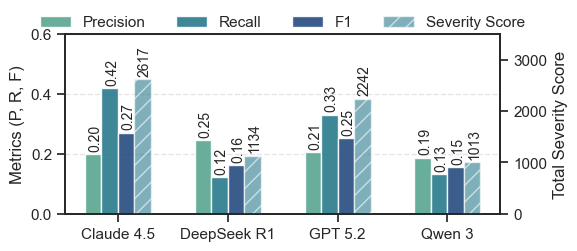

In [ ]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# --- Configuration ---
# Set to True to put CWEs on X-axis, False for Y-axis
HEATMAP_X_IS_CWE = True 
RESULTS_DIR = Path("results")
CWE_LABELS = [
    'CWE-284', 'CWE-435', 'CWE-691', 'CWE-682', 'CWE-697', 
    'CWE-710', 'CWE-664', 'CWE-693', 'CWE-707', 'CWE-703'
]

# Set visual style and font
sns.set_theme(style="ticks")
# To change font, you can set "font.family". 
# Common academic fonts: "Times New Roman" (serif), "Arial" (sans-serif), "Helvetica".
# Ensure the font is installed on your system.
plt.rcParams.update({
    'font.size': 14,
    # 'font.family': 'CMU Serif',  # Change to your preferred font
    'pdf.fonttype': 42, # Type 42 (TrueType) ensures fonts are embeddable in PDFs
    'ps.fonttype': 42   
})


detail_reports = {}
report_files = sorted(list(RESULTS_DIR.glob("*.json")))

print(f"Loading {len(report_files)} reports from {RESULTS_DIR}...")

for f in report_files:
    try:
        with open(f, 'r') as fd:
            data = json.load(fd)
            # Assuming Report model is defined in the previous cell
            report = Report(**data)
            detail_reports[report.model] = report
    except Exception as e:
        print(f"Failed to load {f.name}: {e}")

if not detail_reports:
    print("No reports loaded. Check directory.")
else:
    print(f"Loaded models: {list(detail_reports.keys())}")

print("\n--- Model Performance Summary ---")

model_name_map = {
    'claude45': 'Claude 4.5',
    'deepseek-r1': 'DeepSeek R1',
    'gpt52': 'GPT 5.2',
    'qwen3': 'Qwen 3'
}

for model, report in detail_reports.items():
    display_name = model_name_map.get(model, model)
    
    total_tp = sum(rec.tp_size for rec in report.record)
    total_p = sum(rec.p_size for rec in report.record)
    total_t = sum(rec.t_size for rec in report.record)
    
    print(f"Model: {display_name}")
    print(f"  Token Usage:")
    print(f"    - Input Tokens:      {report.total_prompt_tokens:,}")
    print(f"    - Completion Tokens: {report.total_completion_tokens:,}")
    print(f"    - Total Tokens:      {report.total_tokens:,}")
    print(f"  Performance:")
    print(f"    - Scan Time (s):     {report.total_scan_time:.2f}")
    print(f"    - TP Size:           {total_tp}")
    print(f"    - P Size (Detected): {total_p}")
    print(f"    - T Size (Ground T): {total_t}")
    print(f"    - Precision:         {report.h_precision:.4f}")
    print(f"    - Recall:            {report.h_recall:.4f}")
    print(f"    - F1 Score:          {report.h_f1:.4f}")
    print(f"    - Severity Score:    {report.score:.2f}")
    print("-" * 40)


metrics_data = []
score_data = []

for model, report in detail_reports.items():
    display_name = model_name_map.get(model, model) # Use mapped name or original
    
    # Metrics
    metrics_data.append({'Model': display_name, 'Metric': 'Precision', 'Value': report.h_precision})
    metrics_data.append({'Model': display_name, 'Metric': 'Recall', 'Value': report.h_recall})
    metrics_data.append({'Model': display_name, 'Metric': 'F1 Score', 'Value': report.h_f1})
    # Score
    score_data.append({'Model': display_name, 'Score': report.score})

df_metrics = pd.DataFrame(metrics_data)
df_score = pd.DataFrame(score_data)


# Preparing data arrays for matplotlib
models = sorted(list(set(df_metrics['Model'].unique()) | set(df_score['Model'].unique())))

precisions = []
recalls = []
f1s = []
scores = []

for m in models:
    p = df_metrics[(df_metrics['Model'] == m) & (df_metrics['Metric'] == 'Precision')]['Value'].values
    r = df_metrics[(df_metrics['Model'] == m) & (df_metrics['Metric'] == 'Recall')]['Value'].values
    f = df_metrics[(df_metrics['Model'] == m) & (df_metrics['Metric'] == 'F1 Score')]['Value'].values
    s = df_score[df_score['Model'] == m]['Score'].values
    
    precisions.append(p[0] if len(p) > 0 else 0)
    recalls.append(r[0] if len(r) > 0 else 0)
    f1s.append(f[0] if len(f) > 0 else 0)
    scores.append(s[0] if len(s) > 0 else 0)

x = np.arange(len(models))
width = 0.15

# Setup figure
fig, ax1 = plt.subplots(figsize=(6, 2.8))

# Custom Color Palette
color_palette = sns.color_palette("crest")
colors = color_palette

# Plot Metrics on left axis
rects1 = ax1.bar(x - 1.5*width, precisions, width, label='Precision', color=colors[-5], alpha=0.9)
rects2 = ax1.bar(x - 0.5*width, recalls, width, label='Recall', color=colors[-3], alpha=0.9)
rects3 = ax1.bar(x + 0.5*width, f1s, width, label='F1', color=colors[-1], alpha=0.9)

ax1.set_ylabel('Metrics (P, R, F)')
ax1.set_ylim(0, 0.6) 
ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=0)
ax1.grid(True, axis='y', linestyle='--', alpha=0.5)


ax2 = ax1.twinx()

rects4 = ax2.bar(x + 1.5*width, scores, width, label='Severity Score', color=colors[3], hatch='//', alpha=0.6)

ax2.set_ylabel('Total Severity Score')
ax2.set_ylim(0, 3500) 
ax2.grid(False)

# Add value labels
def autolabel(rects, ax, fmt='{:.2f}'):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate(fmt.format(height),
                    xy=(rect.get_x() + rect.get_width() / 2 +0.02, height),
                    xytext=(0, 2),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, rotation=90)

autolabel(rects1, ax1)
autolabel(rects2, ax1)
autolabel(rects3, ax1)
autolabel(rects4, ax2, fmt='{:.0f}') # Different format for score

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
all_lines = lines1 + lines2
all_labels = labels1 + labels2
ax1.legend(all_lines, all_labels, loc='upper center', bbox_to_anchor=(0.5, 1.18), ncol=4, frameon=False)

plt.tight_layout()
# Save to PDF with 0 margin
plt.savefig("rq5_performance.pdf", format='pdf', bbox_inches='tight', pad_inches=0)
plt.show()

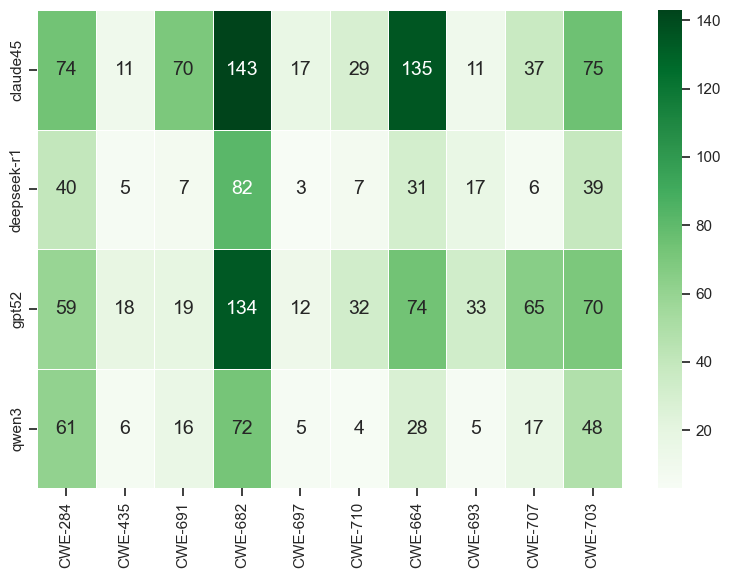

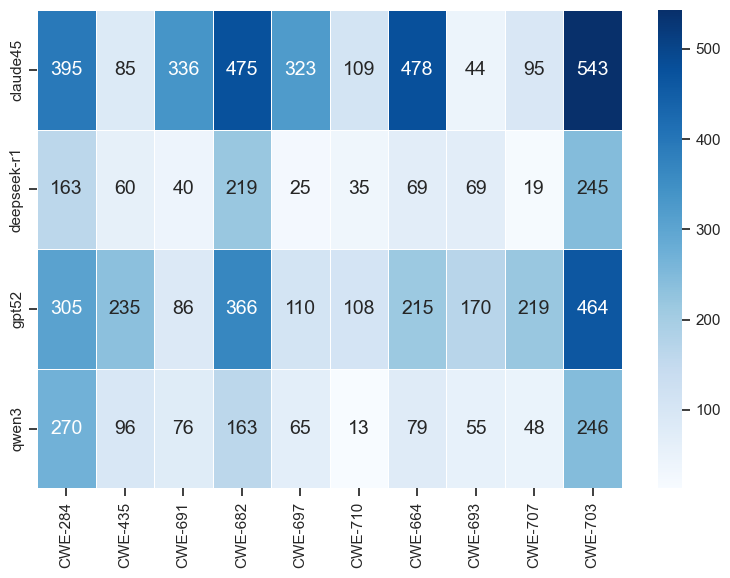

In [4]:

def get_cwe_heatmap_data(reports, target_cwes, mode='tp'):
    """
    mode='tp': Count correctly detected (intersection of detected & ground_truth)
    mode='p': Count all detected (detected set)
    """
    matrix_data = {model: {cwe: 0 for cwe in target_cwes} for model in reports}
    
    for model, report in reports.items():
        for rec in report.record:
            for vp in rec.vuln_pairs:
                if mode == 'tp':
                    # Intersection for True Positives
                    cwes_found = vp.detected.intersection(vp.ground_truth)
                else:
                    # All reported (Positives)
                    cwes_found = vp.detected
                
                for cwe in cwes_found:
                    if cwe in matrix_data[model]:
                        matrix_data[model][cwe] += 1
                        
    return pd.DataFrame(matrix_data).T # Rows: Models, Cols: CWEs


df_heatmap_tp = get_cwe_heatmap_data(detail_reports, CWE_LABELS, mode='tp')
df_heatmap_p  = get_cwe_heatmap_data(detail_reports, CWE_LABELS, mode='p')

# Handle Axis Swap
if not HEATMAP_X_IS_CWE:
    df_heatmap_tp = df_heatmap_tp.T
    df_heatmap_p = df_heatmap_p.T

plt.figure(figsize=(8, 6))
sns.heatmap(df_heatmap_tp, annot=True, fmt="d", cmap="Greens", linewidths=.5)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 6))
sns.heatmap(df_heatmap_p, annot=True, fmt="d", cmap="Blues", linewidths=.5)
plt.tight_layout()
plt.savefig("rq5_heatmap_det.pdf", format='pdf', bbox_inches='tight', pad_inches=0)
plt.show()

Calculating F1 Scores per CWE...


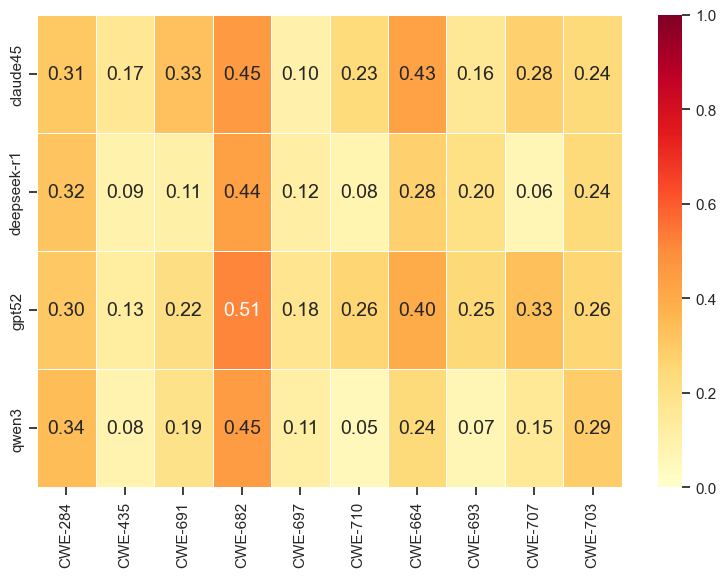

In [5]:
# --- Calculate per-CWE F1 Scores ---
# Initialize counters for each model and each target CWE
cwe_metrics = {model: {cwe: {'tp': 0, 'fp': 0, 'fn': 0} for cwe in CWE_LABELS} for model in detail_reports}

print("Calculating F1 Scores per CWE...")

for model, report in detail_reports.items():
    for rec in report.record:
        for vp in rec.vuln_pairs:
            gt_set = vp.ground_truth
            det_set = vp.detected
            
            # Iterate only through the 10 target Pillar CWEs
            for cwe in CWE_LABELS:
                in_gt = cwe in gt_set
                in_det = cwe in det_set
                
                if in_gt and in_det:
                    # True Positive: In both GT and Detected
                    cwe_metrics[model][cwe]['tp'] += 1
                elif in_det and not in_gt:
                    # False Positive: In Detected but not GT
                    cwe_metrics[model][cwe]['fp'] += 1
                elif in_gt and not in_det:
                    # False Negative: In GT but not Detected
                    cwe_metrics[model][cwe]['fn'] += 1

# Compute F1 values
f1_data = {}
for model in detail_reports:
    f1_data[model] = {}
    for cwe in CWE_LABELS:
        m = cwe_metrics[model][cwe]
        tp = m['tp']
        fp = m['fp']
        fn = m['fn']
        
        # Calculate Precision and Recall
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        
        # Calculate F1
        if (precision + recall) > 0:
            f1 = 2 * (precision * recall) / (precision + recall)
        else:
            f1 = 0.0
        
        f1_data[model][cwe] = f1

# Create DataFrame
df_f1 = pd.DataFrame(f1_data).T # Rows: Models, Cols: CWEs

# Handle Axis Swap based on global config
if not HEATMAP_X_IS_CWE:
    df_f1 = df_f1.T

# --- Plot F1 Heatmap ---
plt.figure(figsize=(8, 6))
# Using 'YlOrRd' colormap: Yellow (low) -> Orange -> Red (high/hot)
sns.heatmap(df_f1, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=.5, vmin=0, vmax=1)
# plt.title(f"Heatmap of F1 Score per CWE Type (Top 10 Pillars) - {'X:CWE' if HEATMAP_X_IS_CWE else 'X:Model'}")

plt.tight_layout()
plt.savefig("rq5_heatmap_f1.pdf", format='pdf', bbox_inches='tight', pad_inches=0)
plt.show()

In [8]:
from datetime import datetime
import numpy as np

# Use a cache to avoid re-reading the same file for different models
audit_date_cache = {}

def get_audit_date(report_path):
    if report_path in audit_date_cache:
        return audit_date_cache[report_path]
    
    try:

        with open(report_path, 'r') as f:
            data = json.load(f)
            date_str = data.get("project_info", {}).get("audit_date")
            if date_str:
                return datetime.strptime(date_str, "%Y-%m-%d")
    except Exception as e:
        # print(f"Error reading date from {report_path}: {e}")
        pass
    
    audit_date_cache[report_path] = None
    return None

print("Extracting audit dates and compiling time-series data...")

temporal_data = []

# Collect data
for model, report in detail_reports.items():
    for rec in report.record:
        # Using the absolute path from the record
        d_date = get_audit_date(rec.report_path)
        
        if d_date:
            temporal_data.append({
                'Model': model,
                'Date': d_date,
                'TP': rec.tp_size,
                'Total_GT': rec.t_size # Total Ground Truth size
            })

df_temporal = pd.DataFrame(temporal_data)

Extracting audit dates and compiling time-series data...


Extracting data for F1 Temporal Analysis...
Plotting F1 Temporal Analysis...


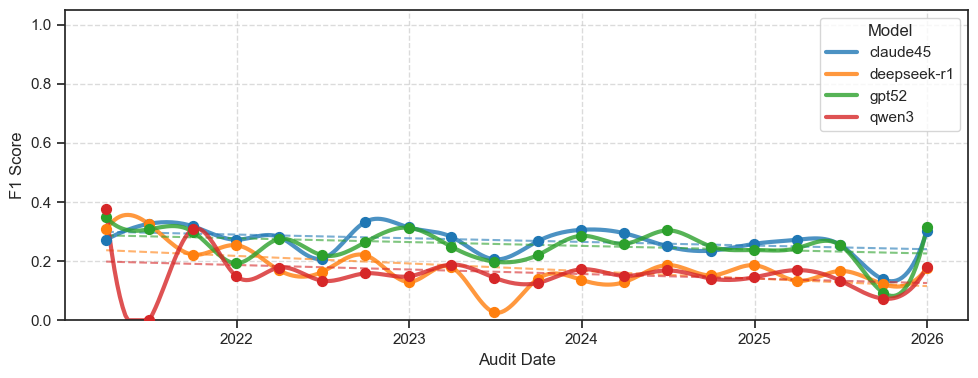

In [9]:
print("Extracting data for F1 Temporal Analysis...")

temporal_data_f1 = []

# Collect data including P_Size (Total Detected) which is needed for Precision -> F1
for model, report in detail_reports.items():
    for rec in report.record:
        # Reuse get_audit_date from previous cell
        d_date = get_audit_date(rec.report_path)
        
        if d_date:
            temporal_data_f1.append({
                'Model': model,
                'Date': d_date,
                'TP': rec.tp_size,
                'Total_GT': rec.t_size,
                'Total_P': rec.p_size 
            })

df_temporal_f1 = pd.DataFrame(temporal_data_f1)

if df_temporal_f1.empty:
    print("No data extracted.")
else:
    # --- Data Processing ---
    df_temporal_f1.set_index('Date', inplace=True)
    
    # Resample by Quarter
    df_resampled_f1 = df_temporal_f1.groupby('Model').resample('QE').sum(numeric_only=True)
    
    # Calculate F1
    MIN_GT_THRESHOLD = 3
    
    def calculate_f1_period(row):
        tp = row['TP']
        gt = row['Total_GT']
        p = row['Total_P']
        
        # Filter noise: Skip periods with very few ground truth cases
        if gt < MIN_GT_THRESHOLD:
            return None
            
        precision = tp / p if p > 0 else 0.0
        recall = tp / gt if gt > 0 else 0.0
        
        if (precision + recall) == 0:
            return 0.0
            
        return 2 * (precision * recall) / (precision + recall)

    df_resampled_f1['F1'] = df_resampled_f1.apply(calculate_f1_period, axis=1)
    
    # Reset index for plotting
    df_resampled_f1 = df_resampled_f1.reset_index()
    
    print("Plotting F1 Temporal Analysis...")

    # --- Plotting ---
    plt.figure(figsize=(10, 4))
    import matplotlib.dates as mdates
    from scipy.interpolate import make_interp_spline

    models_list = df_resampled_f1['Model'].unique()
    palette = sns.color_palette("tab10", len(models_list))
    color_map = dict(zip(models_list, palette))
    
    for model in models_list:
        subset = df_resampled_f1[(df_resampled_f1['Model'] == model) & (df_resampled_f1['F1'].notna())].sort_values('Date')
        
        if subset.empty:
            continue
            
        color = color_map[model]
        
        # 1. Plot Actual Data Points (Scatter)
        plt.scatter(subset['Date'], subset['F1'], color=color, s=50, zorder=5)
        
        # 2. Smooth Curve (B-Spline)
        if len(subset) > 2:
            try:
                x_nums = mdates.date2num(subset['Date'])
                y_vals = subset['F1']
                
                # Dense x-axis
                x_dense = np.linspace(x_nums.min(), x_nums.max(), 300)
                
                # Spline Interpolation
                k = min(3, len(subset) - 1)
                spl = make_interp_spline(x_nums, y_vals, k=k)
                y_dense = spl(x_dense)
                
                # Clip
                y_dense = np.clip(y_dense, 0, 1.02)
                
                # Plot
                plt.plot(mdates.num2date(x_dense), y_dense, color=color, linewidth=3, alpha=0.8, label=model)
            except Exception as e:
                # Fallback
                plt.plot(subset['Date'], subset['F1'], color=color, linewidth=2.5, alpha=0.8, label=model)
        else:
            plt.plot(subset['Date'], subset['F1'], color=color, linewidth=2.5, alpha=0.8, label=model)
            
        # 3. Linear Trend Line (Dashed)
        if len(subset) > 1:
            x_nums = mdates.date2num(subset['Date'])
            y_vals = subset['F1']
            z = np.polyfit(x_nums, y_vals, 1)
            p = np.poly1d(z)
            plt.plot(subset['Date'], p(x_nums), linestyle='--', linewidth=1.5, alpha=0.6, color=color)

    plt.ylabel('F1 Score')
    plt.xlabel('Audit Date')
    plt.ylim(0, 1.05)
    plt.grid(True, linestyle='--', alpha=0.7)
    # plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.legend(title='Model', loc='best')
    plt.tight_layout()
    plt.savefig("rq5_temporal_f1.pdf", format='pdf', bbox_inches='tight', pad_inches=0)
    plt.show()